# Problem 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Part 1

In [197]:
def sim_X(t_max): 
    """
    Simulates X by drawing soujurn times from exp(lam + mu) until the total time exceeds t 
    """
    t = 0
    lam = 5
    mu = 6

    x = [0] # states
    times = [] # transition times 

    while t < t_max:
        # in poisson process, the interarrival times are exponentially distributed
        if x[-1] == 0: # no deaths can occur
            t += np.random.exponential(1/lam) # this function takes the scale parameter as input
            if t > t_max:
                break
            x.append(1) # only birth possible
            times.append(t)
        else:
            t += np.random.exponential(1/(lam + mu)) # rate exiting current state
            if t > t_max:
                break
            u = np.random.uniform(0,1)
            times.append(t)           
            if u < lam / (lam + mu):
                x.append(x[-1] + 1)
            else:
                x.append(x[-1] - 1)

    return  times, x

In [198]:
t = 12
times, x = sim_X(t)
times = np.concat(([0],times,[t]))

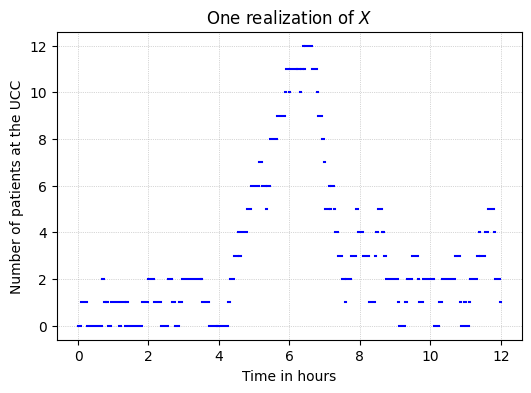

In [199]:
# plotting one realization of X for 12 hours
plt.figure(figsize=(6,4))
for i in range(len(times)-1):
    plt.plot(np.linspace(times[i],times[i+1],2),[x[i]]*2,color='b')

plt.xlabel('Time in hours')
plt.ylabel('Number of patients at the UCC')
plt.grid(linestyle=':', linewidth=0.5)
plt.title('One realization of $X$')
plt.show()

In [200]:
# Estimating L with one simulation of 50 days
L = np.mean(sim_X(1200)[1]) # 1200 hours in 50 days

In [201]:
# Using little's law to estimate W from L. One could pontentially try to find W directly from the simulation. 
W = L/5 # with lambda = 5

In [202]:
print(f'Estimate for mean number of patients at the UCC: {L:.3f} patients')
print(f'Estimate for the mean time spent at the UCC: {W:.3f} hours')

Estimate for mean number of patients at the UCC: 5.091 patients
Estimate for the mean time spent at the UCC: 1.018 hours


In [48]:
from scipy.stats import t
def CI(x):
    """
    Computes 95% CI using t-distribution
    """
    mean = np.mean(x)
    se = np.std(x, ddof=1) / np.sqrt(len(x))
    t_val = t.ppf(0.975, df=len(x)-1)
    return mean - t_val * se, mean + t_val * se

In [336]:
# Finding 95% CIs for L and W
Ls = [np.mean(sim_X(1200)[1]) for _ in range(30)]
Ws = [L/5 for L in Ls]
CI_L = CI(Ls)
CI_W = CI(Ws)

In [337]:
print(f'95% CI for L: [{CI_L[0]:.3f},{CI_L[1]:.3f}]')
print(f'95% CI for W: [{CI_W[0]:.3f},{CI_W[1]:.3f}]')

95% CI for L: [4.905,5.387]
95% CI for W: [0.981,1.077]


In [2]:
# f)
lam = 5
mu = 6
p = np.linspace(0 + 1e-9, 1 - 1e-9, 100)
W_U = 1 / (mu - p*lam)
W_N = mu / ((mu - p*lam) * (mu - lam))

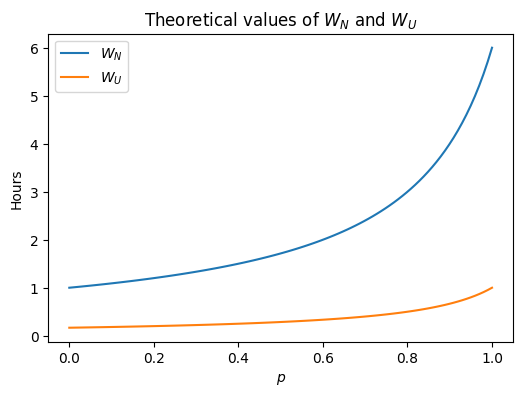

In [ ]:
# Examining how W_N and W_U change with respect to p
plt.figure(figsize=(6,4))
plt.title('Theoretical values of $W_N$ and $W_U$')
plt.plot(p,W_N,label='$W_N$')
plt.plot(p,W_U,label='$W_U$')
plt.legend()
plt.ylabel('Hours')
plt.xlabel('$p$')
plt.show()

### Part 2

In [159]:
# g)
def sim_Y(t_max):
    """
    Simulates Y := (N,U) by drawing soujurn times until the total time exceeds t 
    """
    lam = 5 # arrival rate
    mu = 6 # service rate
    p = 0.8 # probability of urgent patient

    t = 0
    N = [0] # normal patient count
    U = [0] # urgent patient count
    times_N = [] # timestamps for N
    times_U = [] # timestamps for U

    while t < t_max:
        # current state
        u_count = U[-1]
        n_count = N[-1]

        if u_count > 0: # only urgent patients are served
            t += np.random.exponential(1 / (mu + p*lam))
            if t > t_max:
                break
            u = np.random.uniform()
            if u < p * lam / (mu + p*lam):
                U.append(u_count + 1)
            else:
                U.append(u_count - 1)
            times_U.append(t)

        elif n_count > 0: # no urgent patients present so normal patients can be treated
            t += np.random.exponential(1 / (mu + lam))
            if t > t_max:
                break
            u = np.random.uniform()
            if u < p * lam / (mu + lam):
                U.append(1)
                times_U.append(t)
            elif u < lam / (mu + lam): 
                N.append(n_count + 1)
                times_N.append(t)
            else:
                N.append(n_count - 1)
                times_N.append(t)

        else:
            # No patients in system: arrival only
            t += np.random.exponential(1 / lam)
            if t > t_max:
                break
            u = np.random.uniform()
            if u < p:
                U.append(1)
                times_U.append(t)
            else:
                N.append(1)
                times_N.append(t)

    return times_N, times_U, N, U

In [160]:
# Simulating Y for 12 horus
t = 12
times_N, times_U, N, U = sim_Y(t)
times_N = np.concat(([0],times_N,[t]))
times_U = np.concat(([0],times_U,[t]))

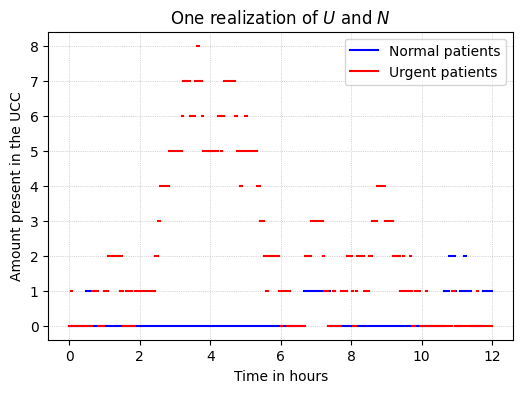

In [161]:
# Plotting one realization
plt.figure(figsize=(6,4))
for i in range(len(times_N)-1):
    plt.plot(np.linspace(times_N[i],times_N[i+1],2),[N[i]]*2,color='b')

for i in range(len(times_U)-1):
    plt.plot(np.linspace(times_U[i],times_U[i+1],2),[U[i]]*2,color='r')

plt.plot([],[],color='b',label='Normal patients')
plt.plot([],[],color='r',label='Urgent patients')
plt.legend()
plt.title('One realization of $U$ and $N$')
plt.ylabel('Amount present in the UCC')
plt.xlabel('Time in hours')
plt.grid(linestyle=':', linewidth=0.5)
plt.show()